<a href="https://colab.research.google.com/github/francji1/01NAEX/blob/main/code/01NAEX_Ex06.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01NAEX - Exercise 06: A single replicate of the $2^k$ design

Data and exercises come from D. C. Montgomery: *Design and Analysis of Experiments*, 8th edition, Chapter 6
(Sections 6.5 and 6.6). Problem numbers follow the 8th edition.

## Learning goals

* Compute all $2^k - 1$ effects of an unreplicated $2^k$ design and explain why the full model has no error term.
* Identify the active effects with the normal (Daniel) and half-normal probability plots and with Lenth's method
  (pseudo standard error, margin of error, simultaneous margin of error, Pareto plot).
* Project the design onto the active factors, fit and check the final model and interpret it with contour plots.
* Recognize the effect of an outlier on the normal plot of effects.
* Use a transformation of the response (log, Box-Cox) and detect dispersion effects from the residuals.

## Setup

Run this cell first. Besides the standard imports it defines helper functions used below:

* `effects_2k()` - contrasts, effects, sums of squares and coded coefficients of a $2^k$ design (Exercise 5).
* `effect_plot()` - normal (or half-normal) probability plot of the effects with a reference line through the small effects.
* `lenth()` - Lenth's pseudo standard error $PSE$, margin of error $ME$ and simultaneous margin of error $SME$.
* `pareto_plot()` - bar chart of the absolute effects with the $ME$ and $SME$ lines.
* `residual_plots()` - normal Q-Q plot of the residuals, residuals versus fitted values and versus each factor, Shapiro-Wilk test.

In [1]:
import itertools

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
from statsmodels.graphics.factorplots import interaction_plot

URL = "https://raw.githubusercontent.com/francji1/01NAEX/main/data/"


def effects_2k(data, response, factors):
    """Contrasts, effects, sums of squares and coded coefficients of a balanced 2^k design.

    `factors` are columns coded -1/+1 (main effects in this order: A, B, C, ...). Rows are in standard order
    (A, B, AB, C, AC, BC, ABC, ...) and are named as in statsmodels formulas ("A:B").
    """
    k = len(factors)
    n = len(data) // 2**k
    rows = []
    for i in range(1, 2**k):
        members = [factors[j] for j in range(k) if i >> j & 1]
        sign = data[members].prod(axis=1)
        contrast = (sign * data[response]).sum()
        rows.append({"term": ":".join(members), "contrast": contrast,
                     "effect": contrast / (n * 2**(k - 1)), "SS": contrast**2 / (n * 2**k)})
    table = pd.DataFrame(rows).set_index("term")
    table["coef"] = table["effect"] / 2
    return table


def effect_plot(effects, half=False, n_label=5, ax=None, title=None):
    """Normal (Daniel) or half-normal probability plot of the effects (a pd.Series indexed by the effect names).

    The reference line is fitted to the smaller half of the effects (through the origin for the half-normal plot).
    The n_label largest effects (in absolute value) are labelled.
    """
    e = (effects.abs() if half else effects).sort_values()
    m = len(e)
    p = (np.arange(1, m + 1) - 0.5) / m
    q = stats.halfnorm.ppf(p) if half else stats.norm.ppf(p)
    x = e.to_numpy(dtype=float)
    small = np.argsort(np.abs(x))[: m // 2 + 1]
    if half:
        b, a = (x[small] @ q[small]) / (q[small] @ q[small]), 0.0
        qq = np.linspace(0, q.max(), 50)
    else:
        b, a = np.polyfit(q[small], x[small], 1)
        qq = np.linspace(q.min(), q.max(), 50)
    if ax is None:
        ax = plt.subplots(figsize=(5, 4))[1]
    ax.scatter(x, q, color="k", s=20)
    ax.plot(a + b * qq, qq, color="tab:red", lw=1)
    largest = effects.abs().sort_values().index[-n_label:] if n_label else []
    for name, xi, qi in zip(e.index, x, q):
        if name in largest:
            ax.annotate(name, (xi, qi), xytext=(4, -3), textcoords="offset points")
    ax.set_xlabel("|effect|" if half else "effect")
    ax.set_ylabel("half-normal quantile" if half else "normal quantile")
    ax.set_title(title or ("Half-normal plot of effects" if half else "Normal probability plot of effects"))
    return ax


def lenth(effects, alpha=0.05):
    """Lenth's method: s0, pseudo standard error, margin of error and simultaneous margin of error."""
    c = np.abs(np.asarray(effects, dtype=float))
    m = len(c)
    s0 = 1.5 * np.median(c)
    pse = 1.5 * np.median(c[c < 2.5 * s0])
    d = m / 3
    me = stats.t.ppf(1 - alpha / 2, d) * pse
    gamma = (1 + (1 - alpha) ** (1 / m)) / 2
    sme = stats.t.ppf(gamma, d) * pse
    return {"s0": s0, "PSE": pse, "ME": me, "SME": sme}


def pareto_plot(effects, alpha=0.05, ax=None):
    """Bars of |effect| sorted by size with Lenth's ME and SME lines."""
    L = lenth(effects, alpha)
    e = effects.abs().sort_values(ascending=False)
    if ax is None:
        ax = plt.subplots(figsize=(9, 3.5))[1]
    ax.bar(e.index, e.to_numpy(), color=np.where(e > L["ME"], "tab:blue", "lightgray"))
    ax.axhline(L["ME"], color="tab:orange", ls="--", label=f"ME = {L['ME']:.2f}")
    ax.axhline(L["SME"], color="tab:red", ls="--", label=f"SME = {L['SME']:.2f}")
    ax.set_ylabel("|effect|")
    ax.tick_params(axis="x", rotation=90)
    ax.legend()
    ax.set_title("Pareto plot of the effects (Lenth)")
    return ax


def residual_plots(model, data, factors):
    """Q-Q plot, residuals vs fitted values and vs each factor; Shapiro-Wilk test of the residuals."""
    res, fit = model.resid, model.fittedvalues
    fig, axes = plt.subplots(1, 2 + len(factors), figsize=(3.3 * (2 + len(factors)), 3.2))
    sm.qqplot(res, line="s", ax=axes[0])
    axes[0].set_title("Normal Q-Q plot")
    axes[1].scatter(fit, res)
    axes[1].axhline(0, color="red", ls="--")
    axes[1].set(xlabel="fitted", ylabel="residual", title="Residuals vs fitted")
    for ax, f in zip(axes[2:], factors):
        ax.scatter(data[f], res)
        ax.axhline(0, color="red", ls="--")
        ax.set(xlabel=f, title=f"Residuals vs {f}")
    plt.tight_layout()
    plt.show()
    print("Shapiro-Wilk on residuals:", stats.shapiro(res))

## 1. Lecture example: filtration rate ($2^4$ design, a single replicate)

Montgomery, Example 6.2: the filtration rate (gal/h) of a resin in a pilot plant. Four factors: $A$ temperature,
$B$ pressure, $C$ concentration of formaldehyde, $D$ stirring rate. One replicate of the $2^4$ design, the 16 runs in random
order. The aim is to **maximize** the filtration rate. The file lists the runs in standard order.

In [2]:
rate = pd.read_csv(URL + "Pilot_Plant_Filtration_Rate_Experiment.csv", sep=";")
factors = list("ABCD")
rate["label"] = ["".join(f.lower() for f in factors if r[f] == 1) or "(1)" for _, r in rate.iterrows()]
rate

,A,B,C,D,Rate,label
0,-1,-1,-1,-1,45,(1)
1,1,-1,-1,-1,71,a
2,-1,1,-1,-1,48,b
3,1,1,-1,-1,65,ab
4,-1,-1,1,-1,68,c
5,1,-1,1,-1,60,ac
6,-1,1,1,-1,80,bc
7,1,1,1,-1,65,abc
8,-1,-1,-1,1,43,d
9,1,-1,-1,1,100,ad


### Main effects and interaction plots

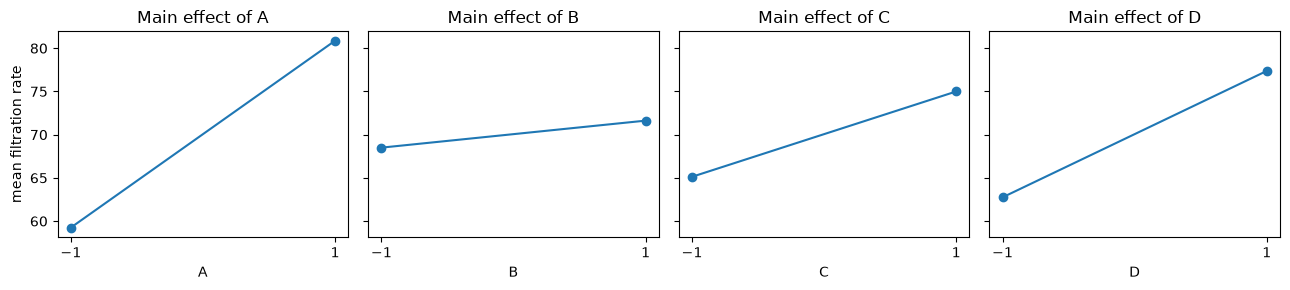

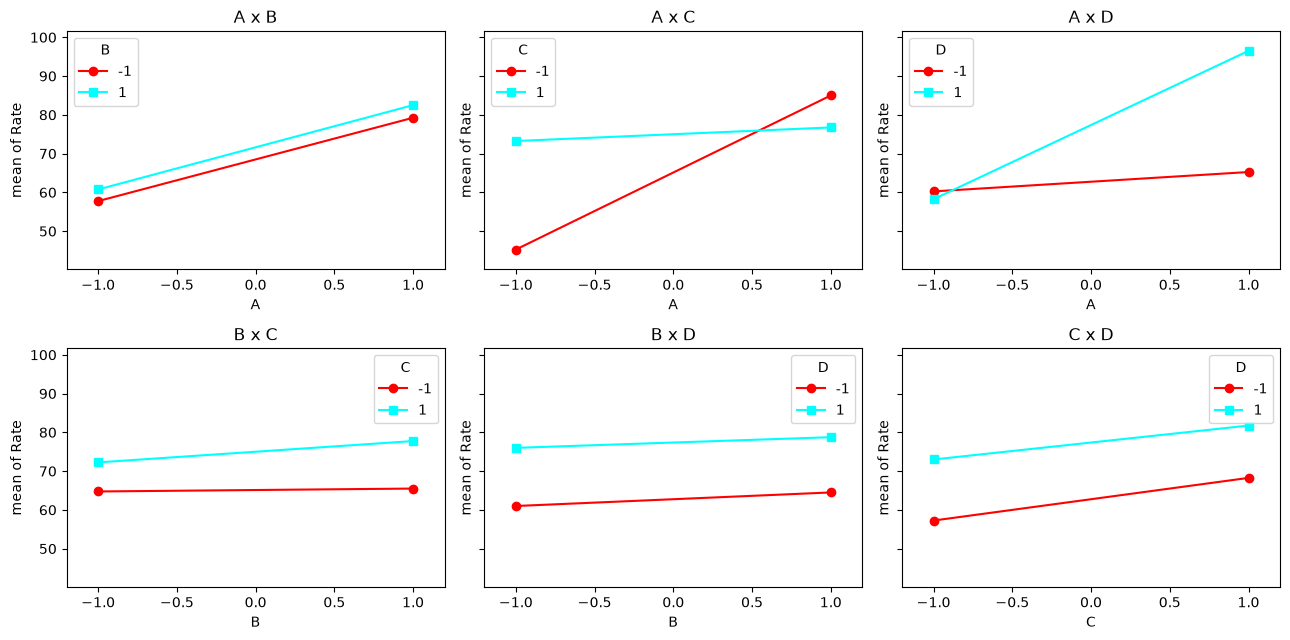

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3), sharey=True)
for ax, f in zip(axes, factors):
    m = rate.groupby(f)["Rate"].mean()
    ax.plot(m.index, m.to_numpy(), "o-")
    ax.set(xticks=[-1, 1], xlabel=f, title=f"Main effect of {f}")
axes[0].set_ylabel("mean filtration rate")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(13, 6.5), sharey=True)
for ax, (f1, f2) in zip(axes.flat, itertools.combinations(factors, 2)):
    interaction_plot(rate[f1], rate[f2], rate["Rate"], ax=ax, markers=["o", "s"])
    ax.set_title(f"{f1} x {f2}")
plt.tight_layout()
plt.show()

The plots suggest large main effects of $A$, $C$, $D$ and interactions $A \times C$ and $A \times D$. The lines of $B$ are
almost flat. But without an error estimate we cannot say which differences are larger than the noise.

### The full model has no error term

In [4]:
import warnings

full = smf.ols("Rate ~ A*B*C*D", data=rate).fit()
print("residual degrees of freedom:", full.df_resid)
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)     # division by the zero residual df
    print(anova_lm(full).round(2))

residual degrees of freedom: 0.0
           df   sum_sq  mean_sq    F  PR(>F)
A         1.0  1870.56  1870.56  0.0     NaN
B         1.0    39.06    39.06  0.0     NaN
A:B       1.0     0.06     0.06  0.0     NaN
C         1.0   390.06   390.06  0.0     NaN
A:C       1.0  1314.06  1314.06  0.0     NaN
B:C       1.0    22.56    22.56  0.0     NaN
A:B:C     1.0    14.06    14.06  0.0     NaN
D         1.0   855.56   855.56  0.0     NaN
A:D       1.0  1105.56  1105.56  0.0     NaN
B:D       1.0     0.56     0.56  0.0     NaN
A:B:D     1.0    68.06    68.06  0.0     NaN
C:D       1.0     5.06     5.06  0.0     NaN
A:C:D     1.0    10.56    10.56  0.0     NaN
B:C:D     1.0    27.56    27.56  0.0     NaN
A:B:C:D   1.0     7.56     7.56  0.0     NaN
Residual  0.0     0.00      inf  NaN     NaN


16 observations, 16 parameters, 0 residual degrees of freedom. The sums of squares are correct, but **statsmodels prints
$F = 0$ and missing $p$-values: these are not test results.** We have to judge the effects without an estimate of $\sigma^2$.

### Effects from the table of signs

In [5]:
eff_table = effects_2k(rate, "Rate", factors)
eff = eff_table["effect"].rename(lambda t: t.replace(":", ""))      # names A, B, AB, ..., ABCD
eff_table.round(3)

,contrast,effect,SS,coef
term,,,,
A,173,21.625,1870.562,10.812
B,25,3.125,39.062,1.562
A:B,1,0.125,0.062,0.062
C,79,9.875,390.062,4.938
A:C,-145,-18.125,1314.062,-9.062
B:C,19,2.375,22.562,1.188
A:B:C,15,1.875,14.062,0.938
D,117,14.625,855.562,7.312
A:D,133,16.625,1105.562,8.312


In [6]:
# the effects are twice the regression coefficients of the full model
check = 2 * full.params.drop("Intercept")
np.allclose(check[eff_table.index], eff_table["effect"])

True

### Normal and half-normal plots of the effects

A negligible effect is $N(0, 4\sigma^2/N)$; the negligible effects lie on a straight line, the active effects are outliers.

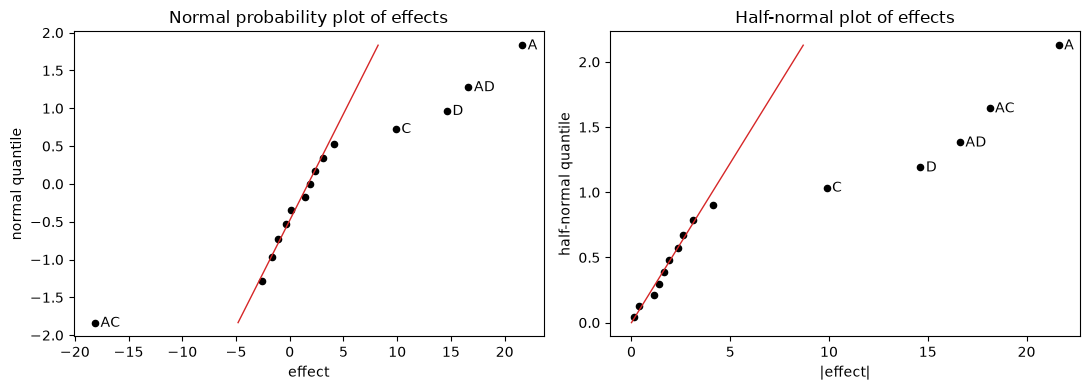

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
effect_plot(eff, ax=axes[0])
effect_plot(eff, half=True, ax=axes[1])
plt.tight_layout()
plt.show()

### Lenth's method and the Pareto plot

{'s0': np.float64(3.938), 'PSE': np.float64(2.625), 'ME': np.float64(6.748), 'SME': np.float64(13.699)}
|effect| > ME:  ['A', 'C', 'AC', 'D', 'AD']
|effect| > SME: ['A', 'AC', 'D', 'AD']


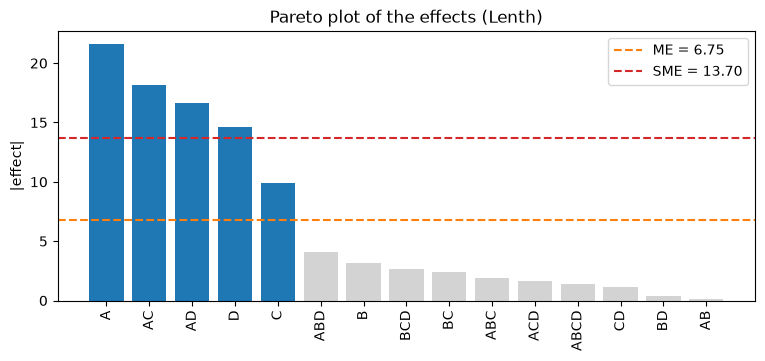

In [8]:
L = lenth(eff)
print({k: round(v, 3) for k, v in L.items()})
print("|effect| > ME: ", list(eff[eff.abs() > L["ME"]].index))
print("|effect| > SME:", list(eff[eff.abs() > L["SME"]].index))
pareto_plot(eff)
plt.show()

$PSE = 2.625$, $ME = 6.75$, $SME = 13.70$ (the same numbers as Montgomery). The effects $A$, $AC$, $AD$, $D$ exceed $SME$,
$C$ exceeds only $ME$. Because $AC$ is clearly active, we keep $C$ (hierarchy). The tentative model is
$A + C + D + AC + AD$; factor $B$ (pressure) does not appear at all.

### Projection into a replicated $2^3$ design

Dropping $B$ projects the single replicate of the $2^4$ into a $2^3$ design in $A$, $C$, $D$ with two replicates, so now
we have 8 degrees of freedom for pure error. (Last year's notebook built this design by stacking two copies of the $2^3$
table and pairing them with the observations in the wrong order. Fitting the model to the original data frame without $B$
avoids that mistake.)

In [9]:
m_acd = smf.ols("Rate ~ A*C*D", data=rate).fit()
anova_lm(m_acd)

,df,sum_sq,mean_sq,F,PR(>F)
A,1.0,1870.5625,1870.5625,83.367688,0.000017
C,1.0,390.0625,390.0625,17.384401,0.003124
A:C,1.0,1314.0625,1314.0625,58.565460,0.000060
D,1.0,855.5625,855.5625,38.130919,0.000267
A:D,1.0,1105.5625,1105.5625,49.272981,0.000110
C:D,1.0,5.0625,5.0625,0.225627,0.647483
A:C:D,1.0,10.5625,10.5625,0.470752,0.512032
Residual,8.0,179.5000,22.4375,NaN,NaN


In [10]:
final = smf.ols("Rate ~ A + C + D + A:C + A:D", data=rate).fit()
print(anova_lm(final).round(4))
print(final.summary().tables[1])
print(f"s = {np.sqrt(final.scale):.3f}, R2 = {final.rsquared:.4f}, R2_adj = {final.rsquared_adj:.4f}")

            df     sum_sq    mean_sq        F  PR(>F)
A          1.0  1870.5625  1870.5625  95.8648  0.0000
C          1.0   390.0625   390.0625  19.9904  0.0012
D          1.0   855.5625   855.5625  43.8469  0.0001
A:C        1.0  1314.0625  1314.0625  67.3447  0.0000
A:D        1.0  1105.5625  1105.5625  56.6592  0.0000
Residual  10.0   195.1250    19.5125      NaN     NaN
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     70.0625      1.104     63.444      0.000      67.602      72.523
A             10.8125      1.104      9.791      0.000       8.352      13.273
C              4.9375      1.104      4.471      0.001       2.477       7.398
D              7.3125      1.104      6.622      0.000       4.852       9.773
A:C           -9.0625      1.104     -8.206      0.000     -11.523      -6.602
A:D            8.3125      1.104      7.527      0.000       5.852   

$$\hat y = 70.06 + 10.81\,x_1 + 4.94\,x_3 + 7.31\,x_4 - 9.06\,x_1x_3 + 8.31\,x_1x_4,$$
with $\hat\sigma = 4.42$ and $R^2 = 0.966$. The residual mean square 19.51 (10 df) is the pure error (8 df) plus the dropped
$CD$ and $ACD$ (2 df). Check the residuals, also against the dropped factor $B$:

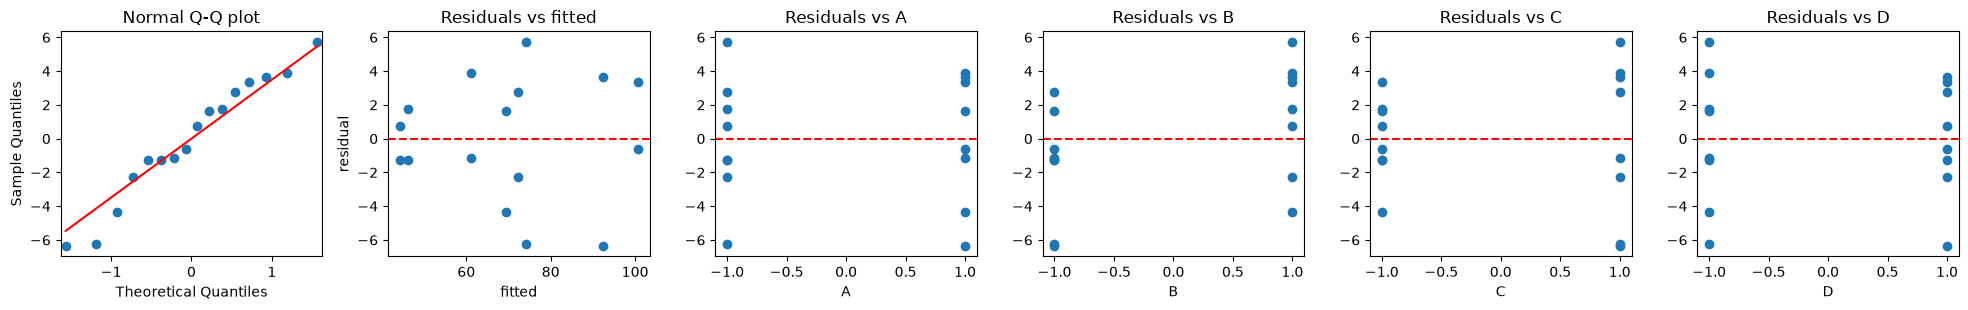

Shapiro-Wilk on residuals: ShapiroResult(statistic=np.float64(0.9534713002974425), pvalue=np.float64(0.5465944420547642))


In [11]:
residual_plots(final, rate, factors)

### Contour plots and the best settings

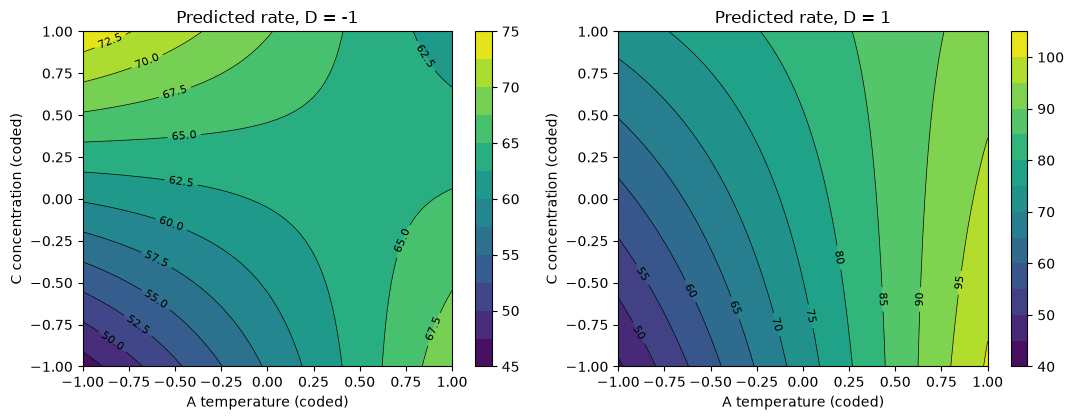

,A,C,D,predicted
5,1,-1,1,100.625
7,1,1,1,92.375
2,-1,1,-1,74.250


In [12]:
g = np.linspace(-1, 1, 41)
A, C = np.meshgrid(g, g)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
for ax, d in zip(axes, [-1, 1]):
    grid = pd.DataFrame({"A": A.ravel(), "C": C.ravel(), "D": d})
    Z = final.predict(grid).to_numpy().reshape(A.shape)
    cs = ax.contourf(A, C, Z, levels=12, cmap="viridis")
    ax.clabel(ax.contour(A, C, Z, levels=12, colors="k", linewidths=0.5), fontsize=8)
    fig.colorbar(cs, ax=ax)
    ax.set(xlabel="A temperature (coded)", ylabel="C concentration (coded)", title=f"Predicted rate, D = {d}")
plt.tight_layout()
plt.show()

corners = pd.DataFrame(list(itertools.product([-1, 1], repeat=3)), columns=["A", "C", "D"])
corners["predicted"] = final.predict(corners)
corners.sort_values("predicted", ascending=False).head(3)

The highest predicted filtration rate (100.6 gal/h) is at high temperature, low concentration of formaldehyde and high
stirring rate ($A = +$, $C = -$, $D = +$); pressure ($B$) can be set at the cheaper level. The model is linear with
interactions and should not be extrapolated outside the cube.

### Pooling only the highest-order interaction?

In [13]:
m_3way = smf.ols("Rate ~ (A + B + C + D)**3", data=rate).fit()
anova_lm(m_3way).round(4)

,df,sum_sq,mean_sq,F,PR(>F)
A,1.0,1870.5625,1870.5625,247.3471,0.0404
B,1.0,39.0625,39.0625,5.1653,0.2639
C,1.0,390.0625,390.0625,51.5785,0.0881
D,1.0,855.5625,855.5625,113.1322,0.0597
A:B,1.0,0.0625,0.0625,0.0083,0.9423
A:C,1.0,1314.0625,1314.0625,173.7603,0.0482
A:D,1.0,1105.5625,1105.5625,146.1901,0.0525
B:C,1.0,22.5625,22.5625,2.9835,0.3341
B:D,1.0,0.5625,0.5625,0.0744,0.8305
C:D,1.0,5.0625,5.0625,0.6694,0.5635


The error term is $ABCD$ with **one** degree of freedom, $F_{0.05,1,1} = 161.4$: even the large effects $C$, $D$ and
$AD$ are not significant. Such a test has almost no power; the normal plot / Lenth's method and the projection are better.

### The effect of an outlier

Suppose the run $cd$ was recorded as 375 instead of 75 (Montgomery, Section 6.5). The error of 300 enters every effect with
weight $\pm 300/8 = \pm 37.5$.

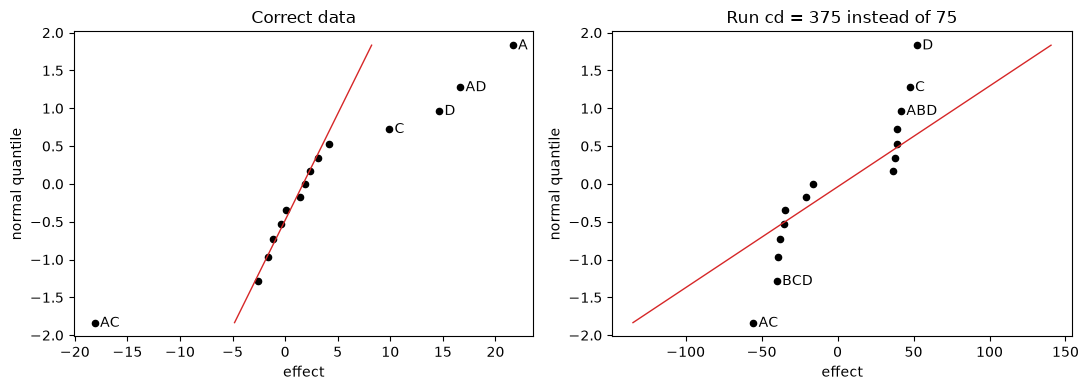

Lenth with the outlier: {'s0': np.float64(58.31), 'PSE': np.float64(58.31), 'ME': np.float64(149.9), 'SME': np.float64(304.31)}


In [14]:
bad = rate.copy()
bad.loc[bad["label"] == "cd", "Rate"] = 375
eff_bad = effects_2k(bad, "Rate", factors)["effect"].rename(lambda t: t.replace(":", ""))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
effect_plot(eff, ax=axes[0], title="Correct data")
effect_plot(eff_bad, ax=axes[1], title="Run cd = 375 instead of 75")
plt.tight_layout()
plt.show()
print("Lenth with the outlier:", {k: round(v, 2) for k, v in lenth(eff_bad).items()})

The effects split into two groups around $\pm 37.5$ with a gap in the middle; there is no straight line through the small
effects and Lenth's method finds nothing. When the normal plot looks like this, check the data first.

----

## 2. Lecture example: data transformation (drill advance rate)

Montgomery, Example 6.3 (Daniel, 1976): a single replicate of a $2^4$ design for the advance rate of a drill. Factors: drill
load ($A$), flow rate ($B$), rotational speed ($C$) and type of drilling mud ($D$). The data are read from Figure 6.19 of the
book and entered in standard order.

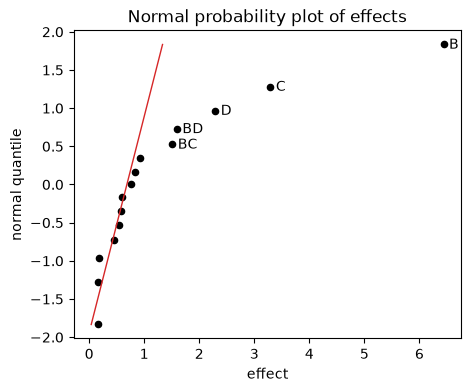

term
AC      0.155
ABC     0.163
BCD     0.175
CD      0.448
ABCD    0.543
ACD     0.585
AB      0.590
ABD     0.760
AD      0.838
A       0.918
BC      1.510
BD      1.592
D       2.290
C       3.293
B       6.438
Name: effect, dtype: float64

In [15]:
drill = pd.DataFrame([r[::-1] for r in itertools.product([-1, 1], repeat=4)], columns=factors)
drill["rate"] = [1.68, 1.98, 4.98, 5.70, 3.24, 3.44, 9.97, 9.07,
                 2.07, 2.44, 7.77, 9.43, 4.09, 4.53, 11.75, 16.30]
eff_drill = effects_2k(drill, "rate", factors)["effect"].rename(lambda t: t.replace(":", ""))
effect_plot(eff_drill)
plt.show()
eff_drill.sort_values().round(3)

On the original scale $B$, $C$, $D$ and the interactions $BC$, $BD$ look active. Fit this model and look at the residuals:

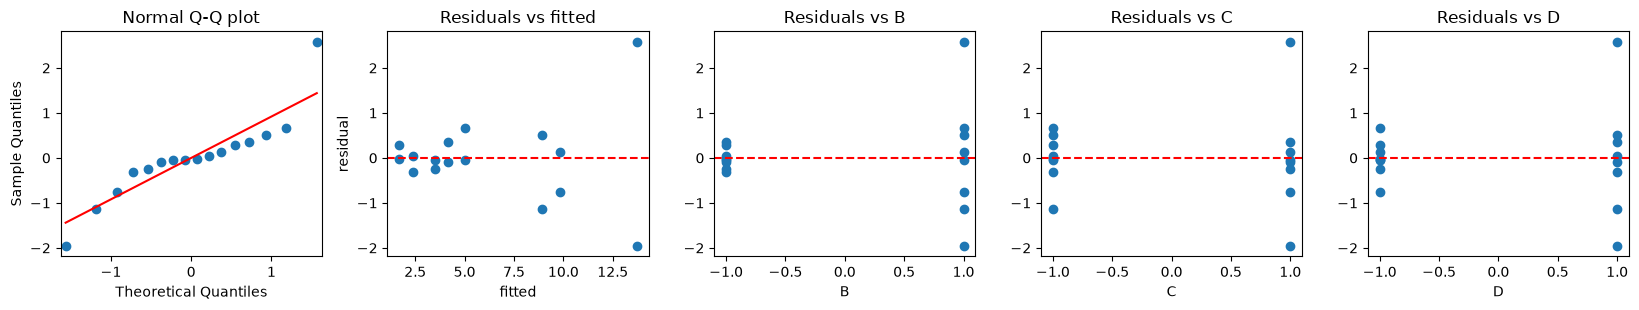

Shapiro-Wilk on residuals: ShapiroResult(statistic=np.float64(0.8811859327432725), pvalue=np.float64(0.040492493314269115))


In [16]:
m_raw = smf.ols("rate ~ B + C + D + B:C + B:D", data=drill).fit()
residual_plots(m_raw, drill, ["B", "C", "D"])

The residuals form a **funnel**: their spread grows with the predicted advance rate. The response is a rate, the effects are
likely multiplicative, so try the log transformation. A quick Box-Cox check: residual sum of squares of the model $B + C + D$
for the scaled power transformation $y^{(\lambda)} = (y^\lambda - 1)/(\lambda \dot y^{\lambda - 1})$ ($\dot y$ = geometric
mean, $\lambda = 0$: $\dot y \ln y$), so that the values are comparable across $\lambda$.

In [17]:
gm = np.exp(np.log(drill["rate"]).mean())
for lam in [1, 0.5, 0, -0.5, -1]:
    if lam == 0:
        y_lam = gm * np.log(drill["rate"])
    else:
        y_lam = (drill["rate"]**lam - 1) / (lam * gm**(lam - 1))
    ssr = smf.ols("y ~ B + C + D", data=drill.assign(y=y_lam)).fit().ssr
    print(f"lambda = {lam:5.1f}: residual SS = {ssr:6.2f}")

lambda =   1.0: residual SS =  32.81
lambda =   0.5: residual SS =  10.55
lambda =   0.0: residual SS =   4.21
lambda =  -0.5: residual SS =   7.87
lambda =  -1.0: residual SS =  23.26


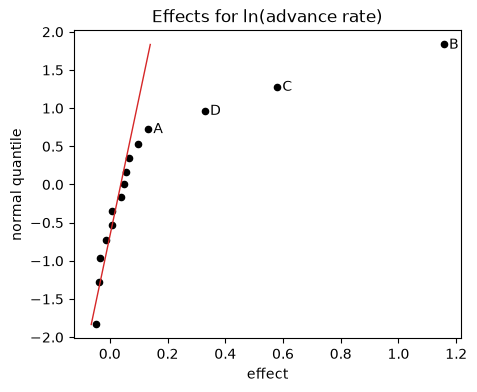

            df  sum_sq  mean_sq         F  PR(>F)
B          1.0  5.3452   5.3452  371.4928  0.0000
C          1.0  1.3389   1.3389   93.0517  0.0000
D          1.0  0.4305   0.4305   29.9224  0.0001
Residual  12.0  0.1727   0.0144       NaN     NaN
R2 = 0.9763


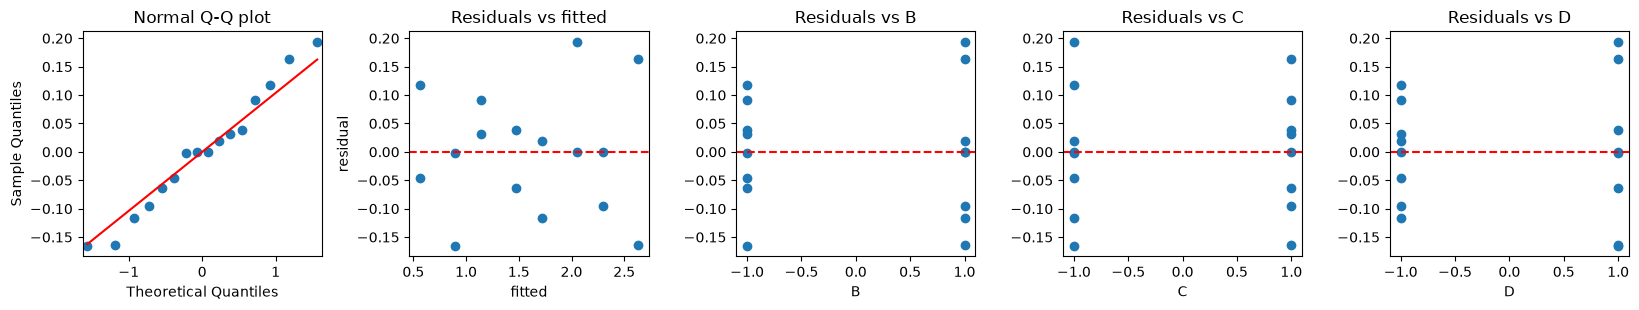

Shapiro-Wilk on residuals: ShapiroResult(statistic=np.float64(0.9681448904190889), pvalue=np.float64(0.8077359536001849))


In [18]:
drill["log_rate"] = np.log(drill["rate"])
eff_log = effects_2k(drill, "log_rate", factors)["effect"].rename(lambda t: t.replace(":", ""))
effect_plot(eff_log, n_label=4, title="Effects for ln(advance rate)")
plt.show()

m_log = smf.ols("log_rate ~ B + C + D", data=drill).fit()
print(anova_lm(m_log).round(4))
print(f"R2 = {m_log.rsquared:.4f}")
residual_plots(m_log, drill, ["B", "C", "D"])

After the log transformation only the main effects $B$, $C$, $D$ are active, the interactions disappeared and the residuals
look fine ($R^2 = 0.976$). Predictions are computed on the log scale and transformed back with `np.exp` (this estimates
the median of the advance rate):

In [19]:
new = pd.DataFrame({"B": [1], "C": [1], "D": [1]})
print("predicted advance rate at B = C = D = +1:", np.exp(m_log.predict(new)).round(2).iloc[0])

predicted advance rate at B = C = D = +1: 13.85


----

## 3. Lecture example: location and dispersion effects (panel process)

Montgomery, Example 6.4: a single replicate of a $2^4$ design in a process producing interior panels for aircraft. Response:
the average number of defects per panel in a press load. Factors: temperature $A$ (295, 325 $^\circ$F), clamp time $B$
(7, 9 min), resin flow $C$ (10, 20), closing time $D$ (15, 30 s). Data from Figure 6.26 of the book, in standard order.

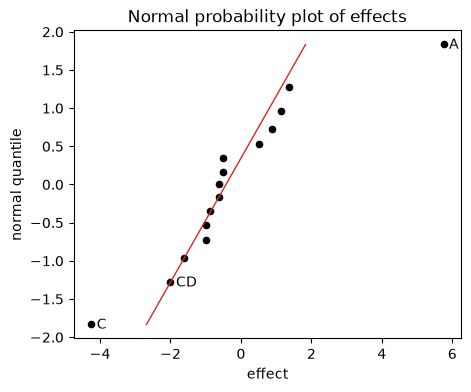

Intercept    6.688
A            2.875
C           -2.125
dtype: float64 R2 = 0.775


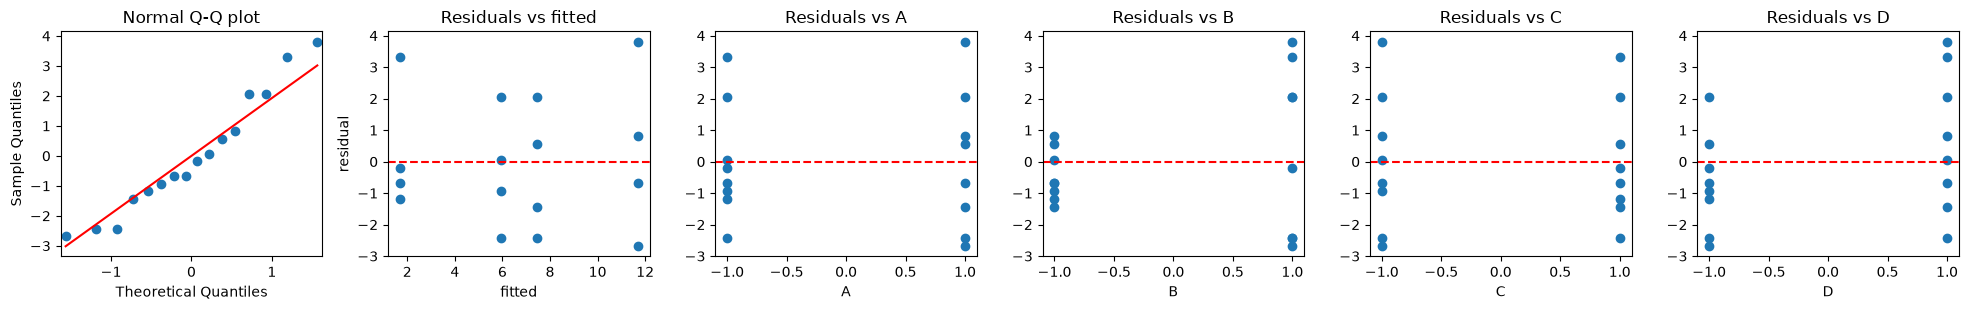

Shapiro-Wilk on residuals: ShapiroResult(statistic=np.float64(0.9427968216833551), pvalue=np.float64(0.3846952959373613))


In [20]:
panel = pd.DataFrame([r[::-1] for r in itertools.product([-1, 1], repeat=4)], columns=factors)
panel["defects"] = [5, 11, 3.5, 9, 0.5, 8, 1.5, 9.5, 6, 12.5, 8, 15.5, 1, 6, 5, 5]
eff_panel = effects_2k(panel, "defects", factors)["effect"].rename(lambda t: t.replace(":", ""))
effect_plot(eff_panel, n_label=3)
plt.show()

m_loc = smf.ols("defects ~ A + C", data=panel).fit()
print(m_loc.params.round(3), f"R2 = {m_loc.rsquared:.3f}")
residual_plots(m_loc, panel, factors)

Location effects: $A = 5.75$ and $C = -4.25$, so low temperature and high resin flow reduce the number of defects. The plot
of the residuals against $B$ (clamp time) shows a much larger spread at the high level of $B$. For every column of the table
of signs we compute the **dispersion effect**
$$F_i^* = \ln \frac{S^2(i^+)}{S^2(i^-)},$$
where $S(i^\pm)$ is the standard deviation of the residuals at the runs where the column is $\pm$.

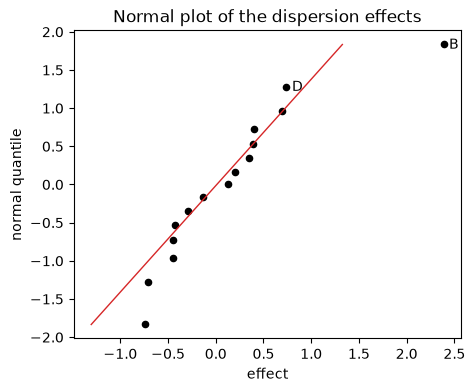

ABCD   -0.74
ACD    -0.71
BC     -0.45
ABC    -0.44
AC     -0.43
C      -0.29
ABD    -0.14
AD      0.13
BCD     0.20
AB      0.35
A       0.39
CD      0.40
BD      0.69
D       0.74
B       2.39
dtype: float64

In [21]:
e = m_loc.resid
Fstar = {}
for t in eff_panel.index:
    s = panel[list(t)].prod(axis=1)
    Fstar[t] = np.log(e[s == 1].var() / e[s == -1].var())
Fstar = pd.Series(Fstar)
effect_plot(Fstar, n_label=2, title="Normal plot of the dispersion effects")
plt.show()
Fstar.sort_values().round(2)

$F_B^* = 2.39$ stands out: clamp time does not change the mean number of defects, but the low clamp time gives a smaller
variability. Recommended: low temperature and high resin flow (location), low clamp time (dispersion).

----

## Assignment

Work on the assignment in class (in pairs, if you like). Whatever you do not finish in class, finish at home as homework.

* Run the notebook above and make sure you understand each step.
* Solve the following problems from Montgomery, *Design and Analysis of Experiments* (8th edition): **6.17, 6.28 with 6.29,
  6.31 with 6.32 and 6.36**; Problem 6.30 is optional.
* Use the normal (or half-normal) plot of the effects together with Lenth's method to choose the model, respect the
  hierarchy, state the hypotheses, the test statistic, its $p$-value and your decision for the final model, check the
  residuals and end each problem with a conclusion in one or two sentences.
* Submit your solved notebook as a pull request into the `HW/` folder of the course repository, named
  `HW/01NAEX_Ex06_HW_<Surname>.ipynb` (see `HW/README.md`). **Deadline: Sunday 8 November 2026** (the next lecture is on
  9 November; Team Project 1 has the same deadline).

### Problem 6.17

An experimenter has run a single replicate of a $2^4$ design. The following effect estimates have been calculated:

| Effect | Estimate | Effect | Estimate | Effect | Estimate |
|---|---|---|---|---|---|
| $A$ | 76.95 | $AB$ | $-51.32$ | $ABC$ | $-2.82$ |
| $B$ | $-67.52$ | $AC$ | 11.69 | $ABD$ | $-6.50$ |
| $C$ | $-7.84$ | $AD$ | 9.78 | $ACD$ | 10.20 |
| $D$ | $-18.73$ | $BC$ | 20.78 | $BCD$ | $-7.98$ |
| | | $BD$ | 14.74 | $ABCD$ | $-6.25$ |
| | | $CD$ | 1.27 | | |

(a) Construct a normal probability plot of these effects.

(b) Identify a tentative model, based on the plot of the effects in part (a).

(c) (Added.) Apply Lenth's method. Does it lead to the same model?

**Solution:**

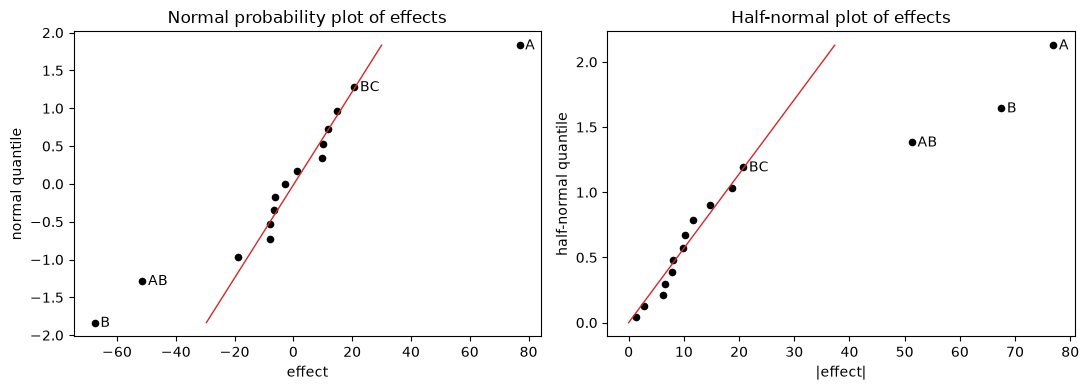

In [22]:
eff617 = pd.Series({
                    "A": 76.95, "B": -67.52, "C": -7.84, "D": -18.73,
                    "AB": -51.32, "AC": 11.69, "AD": 9.78, "BC": 20.78, "BD": 14.74, "CD": 1.27,
                    "ABC": -2.82, "ABD": -6.50, "ACD": 10.20, "BCD": -7.98, "ABCD": -6.25
                })

# (a) normal and half-normal plot
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
effect_plot(eff617, ax=axes[0], n_label=4)
effect_plot(eff617, half=True, ax=axes[1], n_label=4)
plt.tight_layout()
plt.show()

(a), (b) Effects $A$, $B$ and $AB$ are clearly off the line, everything else lies more or less on a straight line
($BC$ and $D$ are at the ends of the line, but still close to it).

Tentative model: $y = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \beta_{12} x_1 x_2 + \varepsilon$
(hierarchy is OK, $A$ and $B$ are both in).

{'s0': np.float64(15.3), 'PSE': np.float64(13.32), 'ME': np.float64(34.24), 'SME': np.float64(69.512)}
|effect| > ME:  ['A', 'B', 'AB']
|effect| > SME: ['A']


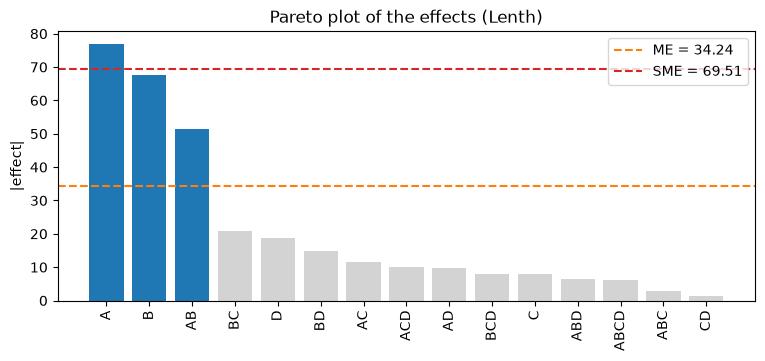

In [23]:
# (c) Lenth's method
L617 = lenth(eff617)
print({k: round(v, 3) for k, v in L617.items()})
print("|effect| > ME: ", list(eff617[eff617.abs() > L617["ME"]].index))
print("|effect| > SME:", list(eff617[eff617.abs() > L617["SME"]].index))
pareto_plot(eff617)
plt.show()

(c) $PSE = 13.32$, $ME = 34.24$, $SME = 69.51$. $A$, $B$, $AB$ exceed $ME$, only $A$ exceeds $SME$ ($B = -67.5$ is just below it).
Lenth gives the same model as the normal plot ($A$, $B$, $AB$); with the stricter SME only $A$ would stay, but $AB$ is large
(51.3) and I keep it together with $B$.

**Conclusion:** the active effects are $A$, $B$ and the interaction $AB$, the tentative model is $A + B + AB$.

### Problems 6.28 and 6.29: process development (yield)

In a process development study on yield, four factors were studied, each at two levels: time ($A$: 2.5 and 3 h),
concentration ($B$: 14 and 18 %), pressure ($C$: 60 and 80 psi) and temperature ($D$: 225 and 250 $^\circ$C). A single
replicate of a $2^4$ design was run. The file `Problem_6_28.csv` contains the factor levels in natural units and the
yield (lbs) in standard order (the actual run order is given in Table P6.7 of the book).

In [24]:
p628 = pd.read_csv(URL + "Problem_6_28.csv")
p628

,Time,Concentration,Pressure,Temperature,Yield
0,2.5,14,60,225,12
1,3.0,14,60,225,18
2,2.5,18,60,225,13
3,3.0,18,60,225,16
4,2.5,14,80,225,17
5,3.0,14,80,225,15
6,2.5,18,80,225,20
7,3.0,18,80,225,15
8,2.5,14,60,250,10
9,3.0,14,60,250,25


**Problem 6.28**

(a) Construct a normal probability plot of the effect estimates. Which factors appear to have large effects?

(b) Conduct an analysis of variance using the normal probability plot in part (a) for guidance in forming an error term.
What are your conclusions?

(c) Write down a regression model relating yield to the important process variables.

(d) Analyze the residuals from this experiment. Does your analysis indicate any potential problems?

(e) Can this design be collapsed into a $2^3$ design with two replicates? If so, sketch the design with the average and range
of yield shown at each point in the cube. Interpret the results.

Hint: first code the factors to $-1$/$+1$, for example `np.where(p628["Time"] == 3, 1, -1)`.

**Solution:**

,contrast,effect,SS,coef
term,,,,
A,36,4.50,81.00,2.250
B,4,0.50,1.00,0.250
A:B,-6,-0.75,2.25,-0.375
C,16,2.00,16.00,1.000
A:C,-34,-4.25,72.25,-2.125
B:C,2,0.25,0.25,0.125
A:B:C,8,1.00,4.00,0.500
D,26,3.25,42.25,1.625
A:D,32,4.00,64.00,2.000


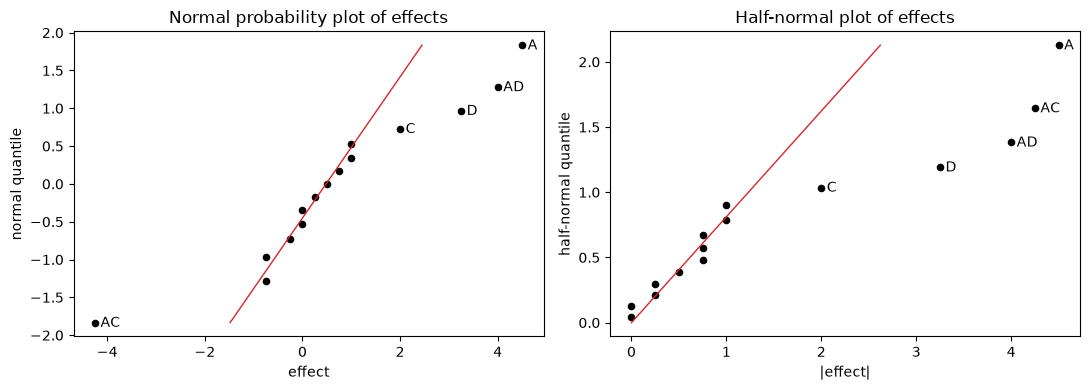

{'s0': np.float64(1.125), 'PSE': np.float64(1.125), 'ME': np.float64(2.892), 'SME': np.float64(5.871)}
|effect| > ME:  ['A', 'AC', 'D', 'AD']
|effect| > SME: []


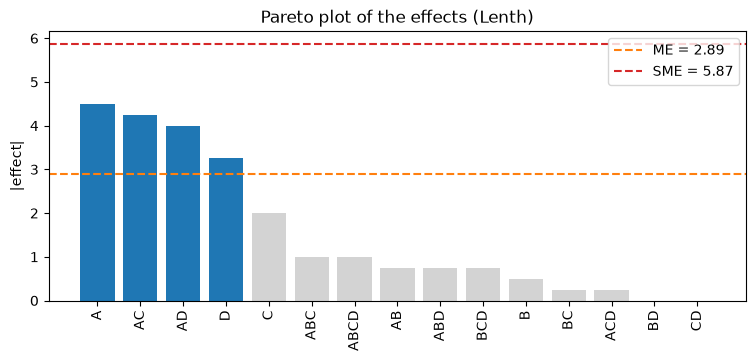

In [25]:
y628 = pd.DataFrame({
    "A": np.where(p628["Time"] == 3, 1, -1),
    "B": np.where(p628["Concentration"] == 18, 1, -1),
    "C": np.where(p628["Pressure"] == 80, 1, -1),
    "D": np.where(p628["Temperature"] == 250, 1, -1),
    "Yield": p628["Yield"],
})
eff628_table = effects_2k(y628, "Yield", factors)
eff628 = eff628_table["effect"].rename(lambda t: t.replace(":", ""))
display(eff628_table.round(3))

# (a)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
effect_plot(eff628, ax=axes[0])
effect_plot(eff628, half=True, ax=axes[1])
plt.tight_layout()
plt.show()

L628 = lenth(eff628)
print({k: round(v, 3) for k, v in L628.items()})
print("|effect| > ME: ", list(eff628[eff628.abs() > L628["ME"]].index))
print("|effect| > SME:", list(eff628[eff628.abs() > L628["SME"]].index))
pareto_plot(eff628)
plt.show()

(a) Large effects: $A$ (time, 4.5), $AC$ (−4.25), $AD$ (4.0), $D$ (temperature, 3.25) and maybe $C$ (pressure, 2.0).
Lenth: $ME = 2.89$, so $A$, $AC$, $D$, $AD$ are active, $C$ is below $ME$, but I keep it because of hierarchy ($AC$ is active).
Concentration $B$ does nothing.

In [26]:
# (b) ANOVA, the remaining effects are pooled into the error
# H0: the effect of the term is zero, test statistic F0 = MS_term / MS_E ~ F(1, 10)
alpha = 0.05
m628 = smf.ols("Yield ~ A + C + D + A:C + A:D", data=y628).fit()
anova628 = anova_lm(m628)
anova628["H0 rejected"] = anova628["PR(>F)"] < alpha
display(anova628.round(4))
print(f"R2 = {m628.rsquared:.4f}, R2_adj = {m628.rsquared_adj:.4f}, s = {np.sqrt(m628.scale):.3f}")

,df,sum_sq,mean_sq,F,PR(>F),H0 rejected
A,1.0,81.00,81.000,49.8462,0.0000,True
C,1.0,16.00,16.000,9.8462,0.0105,True
D,1.0,42.25,42.250,26.0000,0.0005,True
A:C,1.0,72.25,72.250,44.4615,0.0001,True
A:D,1.0,64.00,64.000,39.3846,0.0001,True
Residual,10.0,16.25,1.625,NaN,NaN,False


R2 = 0.9443, R2_adj = 0.9165, s = 1.275


(b) With 10 df for the error ($MS_E = 1.625$) all terms in the model are significant on $\alpha = 0.05$:
$A$ ($F_0 = 49.8$, $p < 0.001$), $C$ ($F_0 = 9.85$, $p = 0.011$), $D$ ($F_0 = 26.0$, $p < 0.001$),
$AC$ ($F_0 = 44.5$, $p < 0.001$), $AD$ ($F_0 = 39.4$, $p < 0.001$). $R^2 = 0.944$.
Time, pressure and temperature affect the yield, but the effect of time depends on pressure and temperature.

In [27]:
# (c) regression model in coded variables
print(m628.params.round(4))

Intercept    17.375
A             2.250
C             1.000
D             1.625
A:C          -2.125
A:D           2.000
dtype: float64


(c) $$\hat y = 17.375 + 2.25\,x_1 + 1.0\,x_3 + 1.625\,x_4 - 2.125\,x_1x_3 + 2.0\,x_1x_4$$
($x_1$ time, $x_3$ pressure, $x_4$ temperature, coded $-1/+1$).

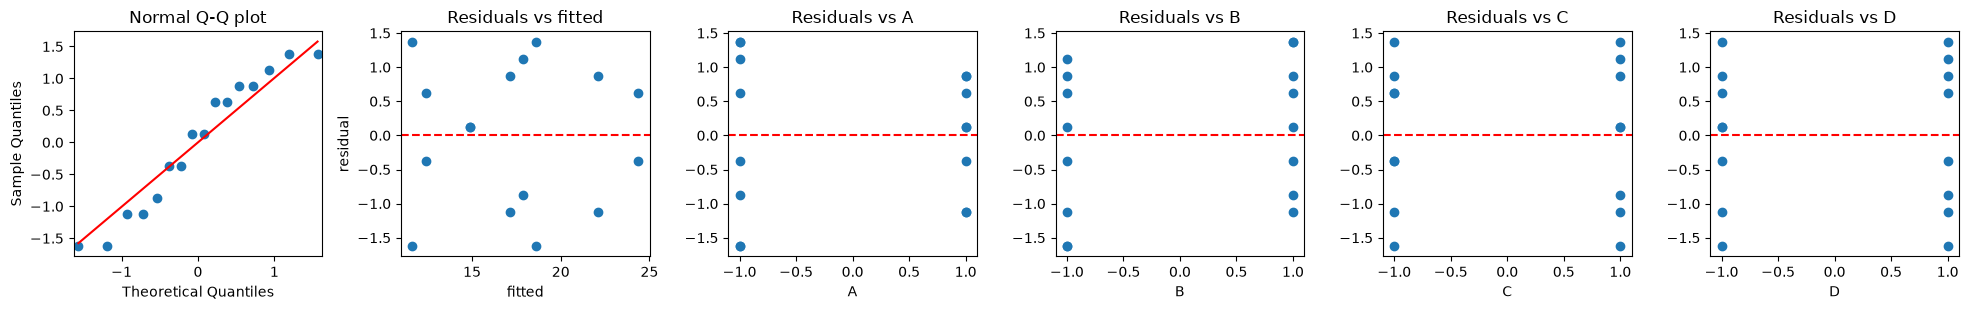

Shapiro-Wilk on residuals: ShapiroResult(statistic=np.float64(0.9226963062905659), pvalue=np.float64(0.1863877016433415))


In [28]:
# (d) residuals
residual_plots(m628, y628, factors)

(d) Q-Q plot is OK, Shapiro-Wilk $p = 0.19$, residuals vs fitted have no strong pattern. Residuals vs $B$ look fine,
so dropping concentration is OK. Maybe a slightly larger spread at some levels, but with 16 runs I don't see a real problem.

,A,C,D,mean,range
0,-1,-1,-1,12.5,1
1,-1,-1,1,11.5,3
2,-1,1,-1,18.5,3
3,-1,1,1,18.0,2
4,1,-1,-1,17.0,2
5,1,-1,1,24.5,1
6,1,1,-1,15.0,0
7,1,1,1,22.0,2


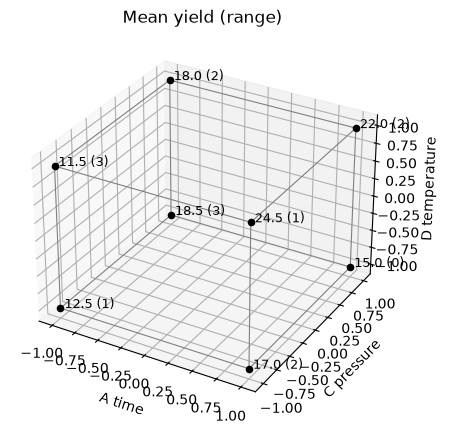

In [29]:
# (e) collapse to 2^3 in A, C, D (B is not active) -> 2 replicates in each corner
cube = y628.groupby(["A", "C", "D"])["Yield"].agg(mean="mean", range=lambda s: s.max() - s.min()).reset_index()
display(cube)

fig = plt.figure(figsize=(6, 5))
ax = fig.add_subplot(projection="3d")
for a_, c_ in [(-1, -1), (-1, 1), (1, -1), (1, 1)]:
    ax.plot([a_, a_], [c_, c_], [-1, 1], color="gray", lw=0.8)
for a_, d_ in [(-1, -1), (-1, 1), (1, -1), (1, 1)]:
    ax.plot([a_, a_], [-1, 1], [d_, d_], color="gray", lw=0.8)
for c_, d_ in [(-1, -1), (-1, 1), (1, -1), (1, 1)]:
    ax.plot([-1, 1], [c_, c_], [d_, d_], color="gray", lw=0.8)
for _, r in cube.iterrows():
    ax.scatter(r["A"], r["C"], r["D"], color="k")
    ax.text(r["A"], r["C"], r["D"], f" {r['mean']:.1f} ({r['range']:.0f})", fontsize=9)
ax.set(xlabel="A time", ylabel="C pressure", zlabel="D temperature", title="Mean yield (range)")
plt.show()

(e) Yes, $B$ is not in the model, so the design collapses into a $2^3$ in $A$, $C$, $D$ with two replicates.
The ranges in the corners are small (0-3), so the noise is small compared to the differences between the corners.
The highest mean yield (24.5) is at long time, low pressure and high temperature ($A+$, $C-$, $D+$); at short time
the high pressure is better (18-18.5), at long time the low pressure is better - this is the $AC$ interaction.

**Conclusion:** yield is driven by time, temperature and pressure with interactions $AC$ and $AD$; concentration is not
important. Best: time 3 h, pressure 60 psi, temperature 250 °C.

**Problem 6.29.** Use the regression model in part (c) of Problem 6.28 to generate a response surface contour plot of yield.
Discuss the practical value of this response surface plot.

**Solution:**

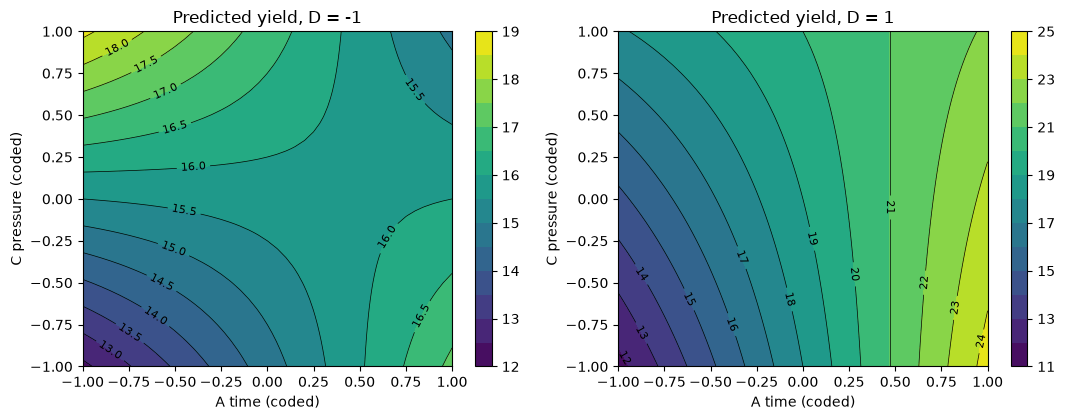

In [30]:
g = np.linspace(-1, 1, 41)
A_, C_ = np.meshgrid(g, g)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
for ax, d in zip(axes, [-1, 1]):
    grid = pd.DataFrame({"A": A_.ravel(), "C": C_.ravel(), "D": d})
    Z = m628.predict(grid).to_numpy().reshape(A_.shape)
    cs = ax.contourf(A_, C_, Z, levels=12, cmap="viridis")
    ax.clabel(ax.contour(A_, C_, Z, levels=12, colors="k", linewidths=0.5), fontsize=8)
    fig.colorbar(cs, ax=ax)
    ax.set(xlabel="A time (coded)", ylabel="C pressure (coded)", title=f"Predicted yield, D = {d}")
plt.tight_layout()
plt.show()

Because of the interactions the contours are curved (twisted plane). At high temperature ($D = +1$) the yield grows towards
long time and low pressure, the maximum predicted yield is $\approx 24.4$ at $A = +1$, $C = -1$, $D = +1$.
Practical value: the plot shows the direction where to go (longer time, lower pressure, higher temperature), but the model is only
first order with interactions from a 2-level design, so it is valid only inside the cube; to really find the optimum
we would need more runs in that direction (and center points to check curvature).

### Problems 6.31 and 6.32: a polymer (molecular weight and viscosity)

An experiment was conducted on a chemical process that produces a polymer. The four factors studied were temperature
($A$: 100 and 120 $^\circ$ C), catalyst concentration ($B$: 4 and 8 %), time ($C$: 20 and 30 min) and pressure ($D$: 60 and
75 psi). Two responses, molecular weight and viscosity, were observed. The file `Problem_6_31.txt` contains the 16 runs of the
$2^4$ design in standard order followed by 4 center points.

**Use only the first 16 runs** (the factorial part). The center points and the test for curvature (part (b) of 6.31)
will come in Lecture 7.

In [31]:
p631 = pd.read_csv(URL + "Problem_6_31.txt", sep=";")
p631 = p631.iloc[:16].copy()          # the 2^4 runs only
p631

,Temperature,Concentration,Time,Pressure,Weight,Viscosity
0,100,4,20,60.0,2400,1400
1,120,4,20,60.0,2410,1500
2,100,8,20,60.0,2315,1520
3,120,8,20,60.0,2510,1630
4,100,4,30,60.0,2615,1380
5,120,4,30,60.0,2625,1525
6,100,8,30,60.0,2400,1500
7,120,8,30,60.0,2750,1620
8,100,4,20,75.0,2400,1400
9,120,4,20,75.0,2390,1525


**Problem 6.31**

(a) Consider only the molecular weight response. Plot the effect estimates on a normal probability scale. What effects
appear important?

(b) Use an analysis of variance to confirm the results from part (a).

(c) Write down a regression model to predict molecular weight as a function of the important variables.

(d) Analyze the residuals and comment on model adequacy.

(e) Repeat parts (a)-(d) using the viscosity response.

**Solution:**

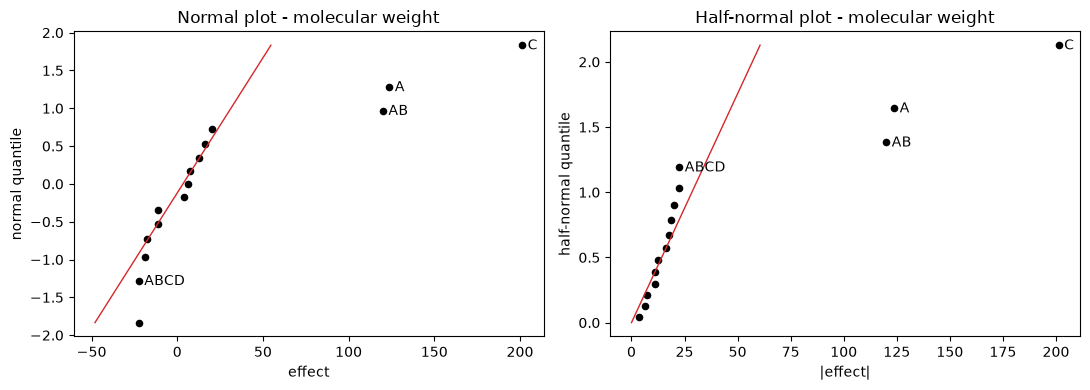

{'s0': np.float64(26.25), 'PSE': np.float64(21.56), 'ME': np.float64(55.43), 'SME': np.float64(112.53)}
|effect| > ME:  ['A', 'AB', 'C']
|effect| > SME: ['A', 'AB', 'C']


term
BC      -22.50
ABCD    -22.50
ACD     -18.75
AD      -17.50
B       -11.25
ABD     -11.25
BCD       3.75
D         6.25
BD        7.50
CD       12.50
ABC      16.25
AC       20.00
AB      120.00
A       123.75
C       201.25
Name: effect, dtype: float64

In [32]:
pol = pd.DataFrame({
    "A": np.where(p631["Temperature"] == 120, 1, -1),
    "B": np.where(p631["Concentration"] == 8, 1, -1),
    "C": np.where(p631["Time"] == 30, 1, -1),
    "D": np.where(p631["Pressure"] == 75, 1, -1),
    "Weight": p631["Weight"].to_numpy(),
    "Viscosity": p631["Viscosity"].to_numpy(),
})

# (a) molecular weight
eff_w = effects_2k(pol, "Weight", factors)["effect"].rename(lambda t: t.replace(":", ""))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
effect_plot(eff_w, ax=axes[0], n_label=4, title="Normal plot - molecular weight")
effect_plot(eff_w, half=True, ax=axes[1], n_label=4, title="Half-normal plot - molecular weight")
plt.tight_layout()
plt.show()
Lw = lenth(eff_w)
print({k: round(v, 2) for k, v in Lw.items()})
print("|effect| > ME: ", list(eff_w[eff_w.abs() > Lw["ME"]].index))
print("|effect| > SME:", list(eff_w[eff_w.abs() > Lw["SME"]].index))
eff_w.sort_values().round(2)

(a) Important effects for molecular weight: $C$ (time, 201.25), $A$ (temperature, 123.75) and $AB$ (120.0). All three are
above $SME = 112.5$. $B$ is small (−11.25), but I add it because of hierarchy ($AB$).

In [33]:
# (b) ANOVA, H0: effect = 0, F0 = MS_term / MS_E
m_w = smf.ols("Weight ~ A + B + C + A:B", data=pol).fit()
anova_w = anova_lm(m_w)
anova_w["H0 rejected"] = anova_w["PR(>F)"] < alpha
display(anova_w.round(4))
print(f"R2 = {m_w.rsquared:.4f}, R2_adj = {m_w.rsquared_adj:.4f}")
# (c)
print(m_w.params.round(3))

,df,sum_sq,mean_sq,F,PR(>F),H0 rejected
A,1.0,61256.25,61256.2500,61.7828,0.0000,True
B,1.0,506.25,506.2500,0.5106,0.4898,False
C,1.0,162006.25,162006.2500,163.3989,0.0000,True
A:B,1.0,57600.00,57600.0000,58.0951,0.0000,True
Residual,11.0,10906.25,991.4773,NaN,NaN,False


R2 = 0.9627, R2_adj = 0.9491
Intercept    2506.250
A              61.875
B              -5.625
C             100.625
A:B            60.000
dtype: float64


(b) H0: effect = 0, $F_0 = MS/MS_E \sim F(1, 11)$. $A$ ($F_0 = 61.8$), $C$ ($F_0 = 163.4$) and $AB$ ($F_0 = 58.1$) are significant ($p < 0.001$), $B$ is not ($p = 0.49$), it is in the model only for hierarchy. $R^2 = 0.963$.

(c) $$\hat y_{weight} = 2506.25 + 61.875\,x_1 - 5.625\,x_2 + 100.625\,x_3 + 60.0\,x_1x_2$$

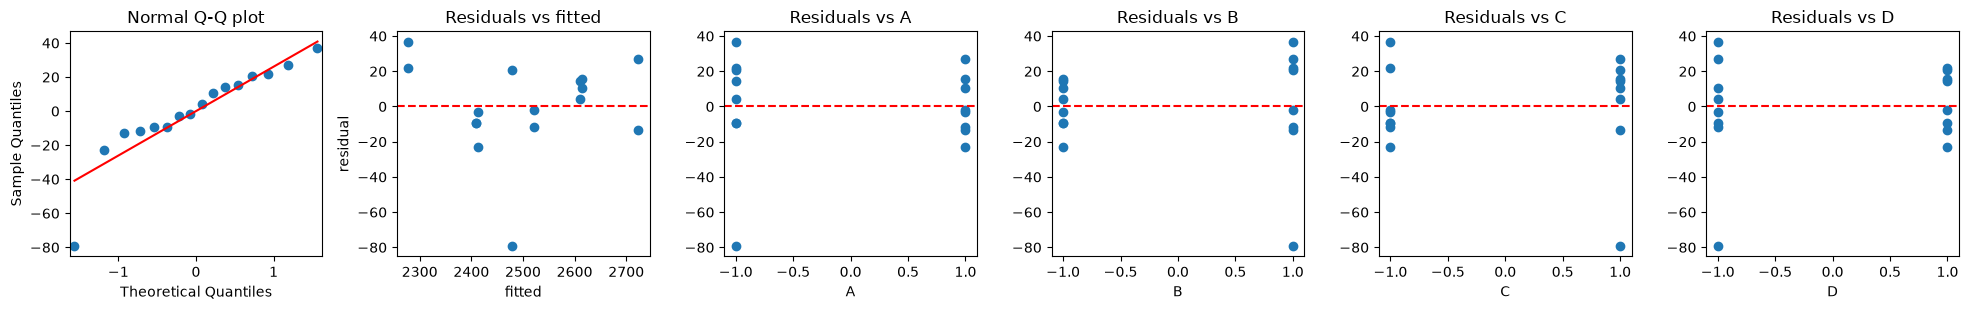

Shapiro-Wilk on residuals: ShapiroResult(statistic=np.float64(0.8680678940885198), pvalue=np.float64(0.025409128481958483))


In [34]:
# (d) residuals
residual_plots(m_w, pol, factors)

In [35]:
# the large negative residual - which run, and what happens without it
i_w = m_w.resid.abs().idxmax()
display(p631.loc[[i_w]].assign(resid=m_w.resid[i_w].round(1)))
m_w2 = smf.ols("Weight ~ A + B + C + A:B", data=pol.drop(i_w)).fit()
print("Shapiro without this run:", round(stats.shapiro(m_w2.resid).pvalue, 3))
print(pd.DataFrame({"all runs": m_w.params, "without run": m_w2.params}).round(2))

,Temperature,Concentration,Time,Pressure,Weight,Viscosity,resid
6,100,8,30,60.0,2400,1500,-79.4


Shapiro without this run: 0.75
           all runs  without run
Intercept   2506.25      2513.47
A             61.88        54.66
B             -5.62         1.59
C            100.62       107.84
A:B           60.00        52.78


(d) Residuals vs fitted and vs the factors show no funnel. Shapiro-Wilk gives $p = 0.025$, but this is caused by **one** run:
run 7 (100 °C, 8 %, 30 min, 60 psi) has residual −79, its "twin" at 75 psi (pressure does nothing) has 2500 instead of 2400.
Without this run Shapiro gives $p = 0.75$ and the coefficients change only a little (see below), so the conclusions stay the same.
It would be good to check this run (typo or real problem in the experiment?).

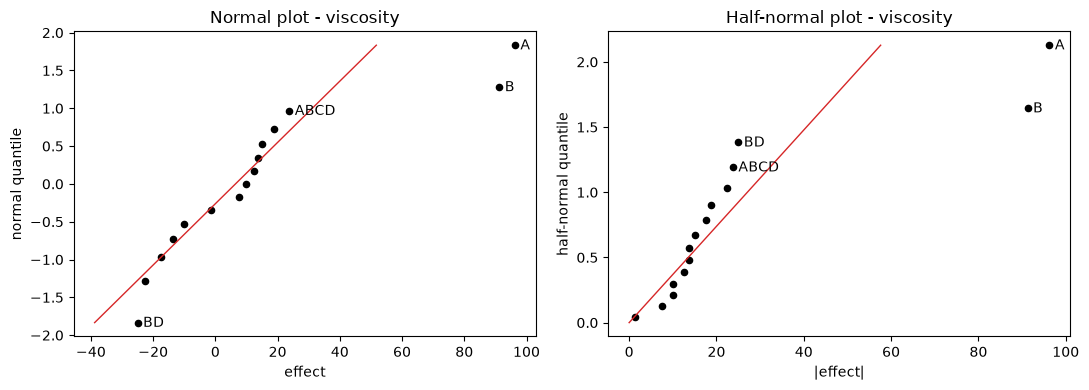

{'s0': np.float64(22.5), 'PSE': np.float64(20.62), 'ME': np.float64(53.02), 'SME': np.float64(107.63)}
|effect| > ME:  ['A', 'B']
|effect| > SME: []


,df,sum_sq,mean_sq,F,PR(>F),H0 rejected
A,1.0,37056.25,37056.2500,35.7334,0.0000,True
B,1.0,33306.25,33306.2500,32.1173,0.0001,True
Residual,13.0,13481.25,1037.0192,NaN,NaN,False


R2 = 0.8392
Intercept    1500.625
A              48.125
B              45.625
dtype: float64


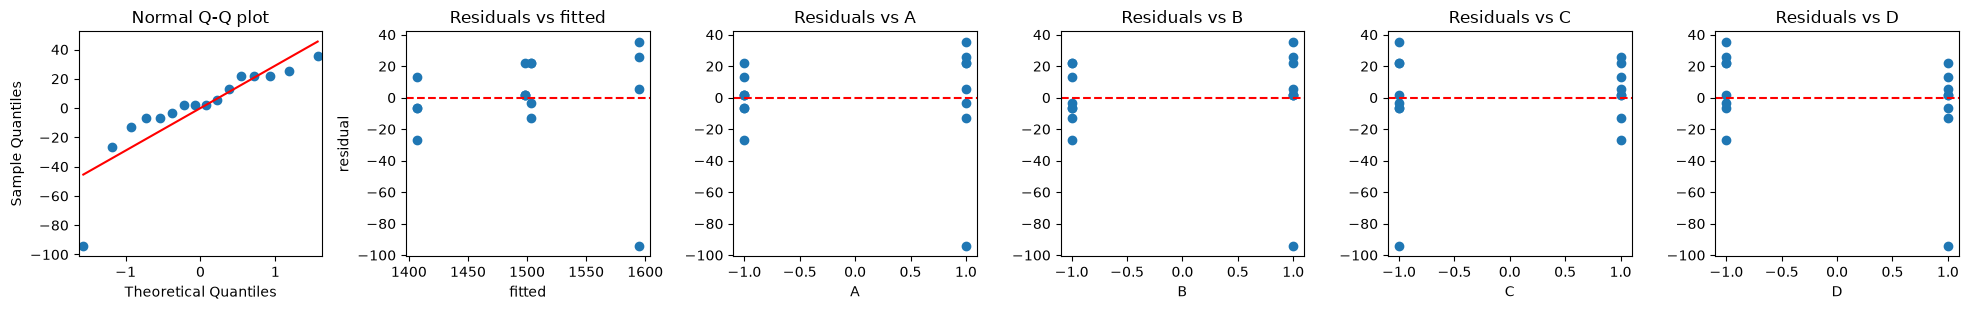

Shapiro-Wilk on residuals: ShapiroResult(statistic=np.float64(0.7933729460211502), pvalue=np.float64(0.0022269603411378554))


In [36]:
# (e) the same for viscosity
eff_v = effects_2k(pol, "Viscosity", factors)["effect"].rename(lambda t: t.replace(":", ""))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
effect_plot(eff_v, ax=axes[0], n_label=4, title="Normal plot - viscosity")
effect_plot(eff_v, half=True, ax=axes[1], n_label=4, title="Half-normal plot - viscosity")
plt.tight_layout()
plt.show()
Lv = lenth(eff_v)
print({k: round(v, 2) for k, v in Lv.items()})
print("|effect| > ME: ", list(eff_v[eff_v.abs() > Lv["ME"]].index))
print("|effect| > SME:", list(eff_v[eff_v.abs() > Lv["SME"]].index))

m_v = smf.ols("Viscosity ~ A + B", data=pol).fit()
anova_v = anova_lm(m_v)
anova_v["H0 rejected"] = anova_v["PR(>F)"] < alpha
display(anova_v.round(4))
print(f"R2 = {m_v.rsquared:.4f}")
print(m_v.params.round(3))
residual_plots(m_v, pol, factors)

In [37]:
i_v = m_v.resid.abs().idxmax()
display(p631.loc[[i_v]].assign(resid=m_v.resid[i_v].round(1)))
m_v2 = smf.ols("Viscosity ~ A + B", data=pol.drop(i_v)).fit()
print("Shapiro without this run:", round(stats.shapiro(m_v2.resid).pvalue, 3))
print(pd.DataFrame({"all runs": m_v.params, "without run": m_v2.params}).round(2))

,Temperature,Concentration,Time,Pressure,Weight,Viscosity,resid
11,120,8,20,75.0,2520,1500,-94.4


Shapiro without this run: 0.254
           all runs  without run
Intercept   1500.63      1507.88
A             48.12        55.38
B             45.62        52.88


(e) Viscosity: only $A$ (96.25) and $B$ (91.25) are clearly off the line, both exceed $ME = 53.0$, but none exceeds $SME = 107.6$.
In the plot they are clearly separated from the rest, so I take $A + B$. ANOVA: $A$ ($F_0 = 35.7$, $p < 0.001$) and
$B$ ($F_0 = 32.1$, $p < 0.001$), both H0 rejected.
$$\hat y_{visc} = 1500.625 + 48.125\,x_1 + 45.625\,x_2$$
$R^2 = 0.839$, lower than for weight. Residuals: Shapiro-Wilk $p = 0.002$, again because of **one** run — run 12 (120 °C, 8 %,
20 min, 75 psi) has viscosity 1500, while the same setting at 60 psi gives 1630 (residual −94). Without it Shapiro $p = 0.25$
and the coefficients are similar. Otherwise the residuals look OK.

**Conclusion:** molecular weight depends on temperature, time and the temperature × concentration interaction; viscosity depends
on temperature and catalyst concentration only (both increase it). Each response has one suspicious run that should be checked.

**Problem 6.32.** Use the regression models for molecular weight and viscosity to answer the following questions.

(a) Construct a response surface contour plot for molecular weight. In what direction would you adjust the process variables
to increase molecular weight?

(b) Construct a response surface contour plot for viscosity. In what direction would you adjust the process variables to
decrease viscosity?

(c) What operating conditions would you recommend if it was necessary to produce a product with molecular weight between
2400 and 2500 and the lowest possible viscosity?

**Solution:**

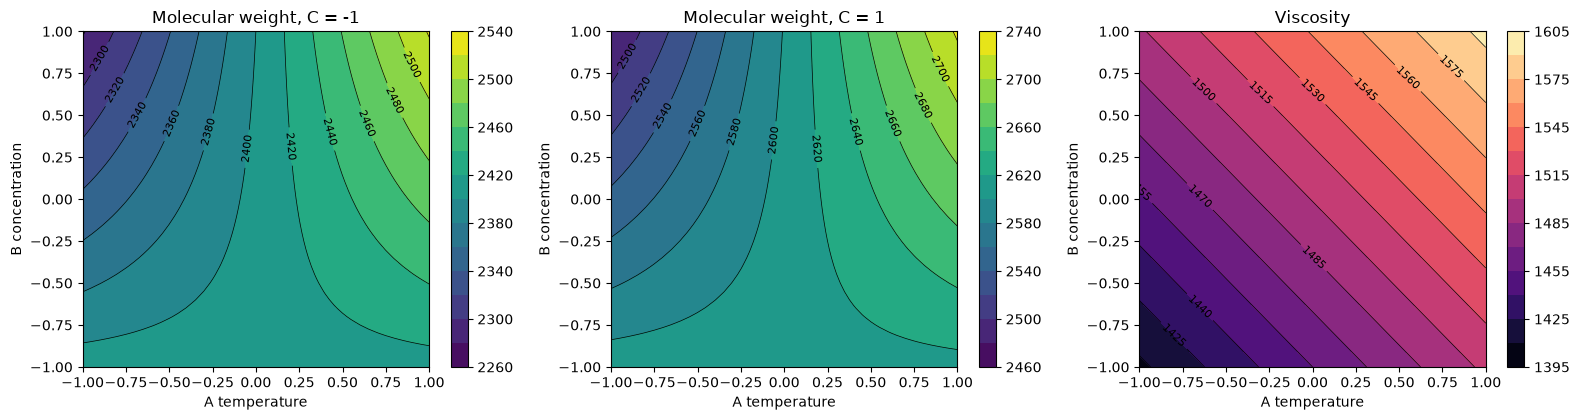

In [38]:
g = np.linspace(-1, 1, 41)
A_, B_ = np.meshgrid(g, g)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
for ax, c in zip(axes[:2], [-1, 1]):
    grid = pd.DataFrame({"A": A_.ravel(), "B": B_.ravel(), "C": c})
    Z = m_w.predict(grid).to_numpy().reshape(A_.shape)
    cs = ax.contourf(A_, B_, Z, levels=12, cmap="viridis")
    ax.clabel(ax.contour(A_, B_, Z, levels=12, colors="k", linewidths=0.5), fontsize=8)
    fig.colorbar(cs, ax=ax)
    ax.set(xlabel="A temperature", ylabel="B concentration", title=f"Molecular weight, C = {c}")

grid = pd.DataFrame({"A": A_.ravel(), "B": B_.ravel()})
Zv = m_v.predict(grid).to_numpy().reshape(A_.shape)
cs = axes[2].contourf(A_, B_, Zv, levels=12, cmap="magma")
axes[2].clabel(axes[2].contour(A_, B_, Zv, levels=12, colors="k", linewidths=0.5), fontsize=8)
fig.colorbar(cs, ax=axes[2])
axes[2].set(xlabel="A temperature", ylabel="B concentration", title="Viscosity")
plt.tight_layout()
plt.show()

(a) Molecular weight increases with time ($C$) - longer time always helps. Because of $AB$ the effect of temperature depends on
concentration: at high concentration ($B+$) higher temperature increases the weight a lot, at low concentration the temperature
has almost no effect. To increase weight: long time, high temperature and high catalyst concentration.

(b) Viscosity is a plane, it decreases towards low temperature and low concentration ($A-$, $B-$).

In [39]:
# (c) weight between 2400 and 2500 with the lowest viscosity
g = np.linspace(-1, 1, 21)
grid = pd.DataFrame(list(itertools.product(g, g, g)), columns=["A", "B", "C"])
grid["weight"] = m_w.predict(grid)
grid["viscosity"] = m_v.predict(grid)
ok = grid[(grid["weight"] >= 2400) & (grid["weight"] <= 2500)]
ok.sort_values("viscosity").head(8).round(2)

,A,B,C,weight,viscosity
0,-1.0,-1.0,-1.0,2409.38,1406.88
1,-1.0,-1.0,-0.9,2419.44,1406.88
2,-1.0,-1.0,-0.8,2429.50,1406.88
3,-1.0,-1.0,-0.7,2439.56,1406.88
4,-1.0,-1.0,-0.6,2449.63,1406.88
5,-1.0,-1.0,-0.5,2459.69,1406.88
6,-1.0,-1.0,-0.4,2469.75,1406.88
7,-1.0,-1.0,-0.3,2479.81,1406.88


(c) The lowest viscosity is at $A = -1$, $B = -1$ (about 1407). At this point the weight is $\approx 2506 - 62 + 6 + 60 + 100.6\,x_3$,
so with time around $x_3 \approx -0.1$ to $-1$ we get weight in 2400-2500 (at $x_3 = -1$ weight is about 2411).
Recommended: temperature 100 °C, catalyst 4 %, time roughly 20-24 min (coded $C$ between −1 and about −0.1), pressure does not matter
(e.g. the cheaper one). This is only a prediction from the model, it should be confirmed by a few runs.

### Problem 6.36: resistivity of a silicon wafer

Resistivity on a silicon wafer is influenced by several factors. The results of a single replicate of a $2^4$ factorial
experiment performed during a critical processing step are (standard order):

In [40]:
p636 = pd.DataFrame([r[::-1] for r in itertools.product([-1, 1], repeat=4)], columns=list("ABCD"))
p636["resistivity"] = [1.92, 11.28, 1.09, 5.75, 2.13, 9.53, 1.03, 5.35,
                       1.60, 11.73, 1.16, 4.68, 2.16, 9.11, 1.07, 5.30]
p636

,A,B,C,D,resistivity
0,-1,-1,-1,-1,1.92
1,1,-1,-1,-1,11.28
2,-1,1,-1,-1,1.09
3,1,1,-1,-1,5.75
4,-1,-1,1,-1,2.13
5,1,-1,1,-1,9.53
6,-1,1,1,-1,1.03
7,1,1,1,-1,5.35
8,-1,-1,-1,1,1.60
9,1,-1,-1,1,11.73


**Problem 6.36**

(a) Estimate the factor effects. Plot the effect estimates on a normal probability plot and select a tentative model.

(b) Fit the model identified in part (a) and analyze the residuals. Is there any indication of model inadequacy?

(c) Repeat the analysis from parts (a) and (b) using $\ln(y)$ as the response variable. Is there an indication that the
transformation has been useful?

(d) Fit a model in terms of the coded variables that can be used to predict the resistivity.

**Solution:**

,contrast,effect,SS,coef
term,,,,
A,50.57,6.3212,159.8328,3.1606
B,-24.03,-3.0038,36.0901,-1.5019
A:B,-17.11,-2.1388,18.2970,-1.0694
C,-3.53,-0.4412,0.7788,-0.2206
A:C,-4.77,-0.5962,1.4221,-0.2981
B:C,3.67,0.4587,0.8418,0.2294
A:B:C,5.51,0.6887,1.8975,0.3444
D,-1.27,-0.1587,0.1008,-0.0794
A:D,-0.91,-0.1137,0.0518,-0.0569


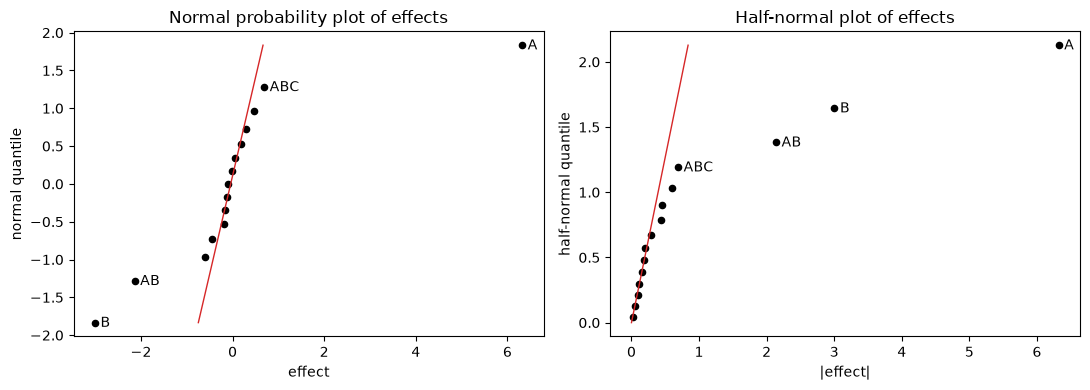

{'s0': np.float64(0.426), 'PSE': np.float64(0.287), 'ME': np.float64(0.737), 'SME': np.float64(1.497)}
|effect| > ME:  ['A', 'B', 'AB']
|effect| > SME: ['A', 'B', 'AB']


In [41]:
eff636_table = effects_2k(p636, "resistivity", factors)
eff636 = eff636_table["effect"].rename(lambda t: t.replace(":", ""))
display(eff636_table.round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
effect_plot(eff636, ax=axes[0], n_label=4)
effect_plot(eff636, half=True, ax=axes[1], n_label=4)
plt.tight_layout()
plt.show()
L636 = lenth(eff636)
print({k: round(v, 3) for k, v in L636.items()})
print("|effect| > ME: ", list(eff636[eff636.abs() > L636["ME"]].index))
print("|effect| > SME:", list(eff636[eff636.abs() > L636["SME"]].index))

(a) The biggest effects are $A$ and $B$, then $AB$; the others are close to zero. Tentative model: $A + B + AB$.

,df,sum_sq,mean_sq,F,PR(>F),H0 rejected
A,1.0,159.8328,159.8328,333.0877,0.0,True
B,1.0,36.0901,36.0901,75.2108,0.0,True
A:B,1.0,18.2970,18.2970,38.1305,0.0,True
Residual,12.0,5.7582,0.4799,NaN,NaN,False


R2 = 0.9738


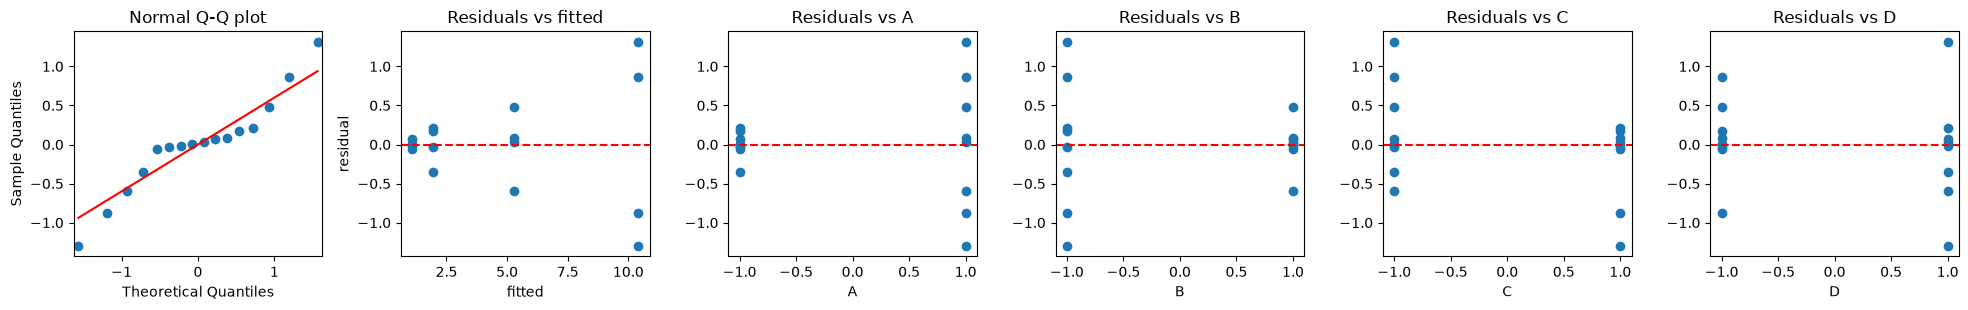

Shapiro-Wilk on residuals: ShapiroResult(statistic=np.float64(0.9428466535306188), pvalue=np.float64(0.3853569932689265))


In [42]:
# (b) H0: effect = 0, F0 = MS_term / MS_E
m636 = smf.ols("resistivity ~ A + B + A:B", data=p636).fit()
anova636 = anova_lm(m636)
anova636["H0 rejected"] = anova636["PR(>F)"] < alpha
display(anova636.round(4))
print(f"R2 = {m636.rsquared:.4f}")
residual_plots(m636, p636, factors)

(b) All three terms are significant ($A$: $F_0 = 333$, $B$: $F_0 = 75.2$, $AB$: $F_0 = 38.1$, all $p < 0.001$, $R^2 = 0.974$, Shapiro $p = 0.39$), but the residuals are not nice: the spread of the residuals grows with the fitted value
(funnel) and is much bigger at $A = +1$ — the variance is not constant. This is a sign of model inadequacy, a transformation could help.

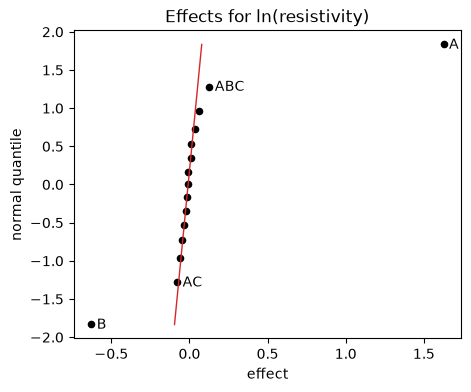

{'s0': np.float64(0.054), 'PSE': np.float64(0.053), 'ME': np.float64(0.137), 'SME': np.float64(0.278)}
|effect| > ME:  ['A', 'B']
|effect| > SME: ['A', 'B']


,df,sum_sq,mean_sq,F,PR(>F),H0 rejected
A,1.0,10.5721,10.5721,962.9454,0.0,True
B,1.0,1.5803,1.5803,143.9414,0.0,True
Residual,13.0,0.1427,0.0110,NaN,NaN,False


R2 = 0.9884


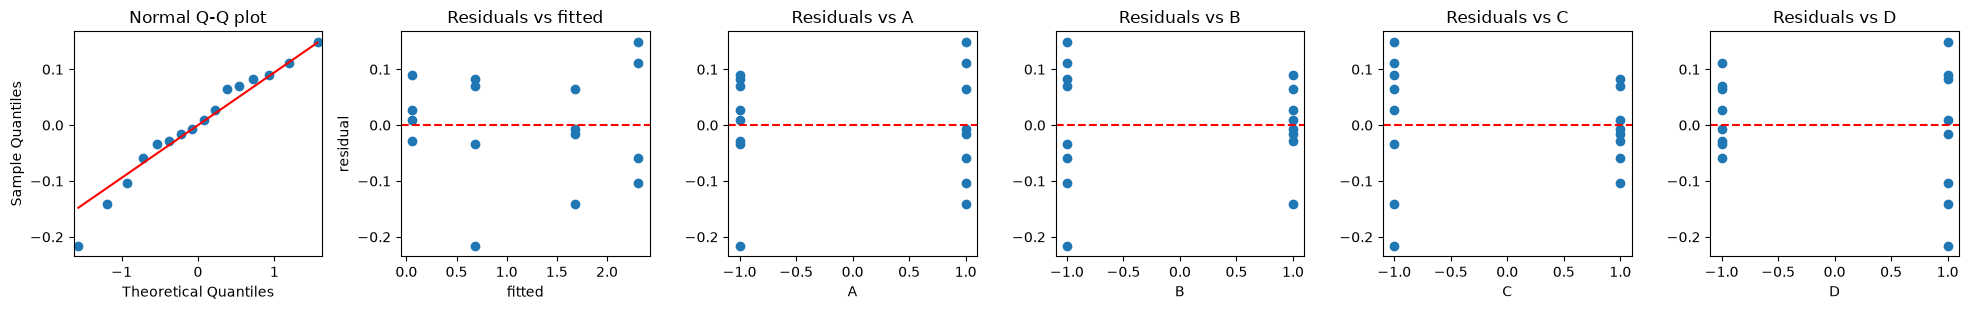

Shapiro-Wilk on residuals: ShapiroResult(statistic=np.float64(0.96679471260315), pvalue=np.float64(0.7843979541734767))


In [43]:
# (c) ln(y)
p636["log_res"] = np.log(p636["resistivity"])
eff636_log = effects_2k(p636, "log_res", factors)["effect"].rename(lambda t: t.replace(":", ""))
effect_plot(eff636_log, n_label=4, title="Effects for ln(resistivity)")
plt.show()
L636l = lenth(eff636_log)
print({k: round(v, 3) for k, v in L636l.items()})
print("|effect| > ME: ", list(eff636_log[eff636_log.abs() > L636l["ME"]].index))
print("|effect| > SME:", list(eff636_log[eff636_log.abs() > L636l["SME"]].index))

m636_log = smf.ols("log_res ~ A + B", data=p636).fit()
anova636_log = anova_lm(m636_log)
anova636_log["H0 rejected"] = anova636_log["PR(>F)"] < alpha
display(anova636_log.round(4))
print(f"R2 = {m636_log.rsquared:.4f}")
residual_plots(m636_log, p636, factors)

(c) On the log scale only $A$ and $B$ are large, the interaction $AB$ is gone (it was caused by the multiplicative effects).
The model $A + B$ has both terms highly significant ($F_0 = 963$ and $144$, $p < 0.001$), $R^2 = 0.988$ with only 2 terms, Shapiro $p = 0.78$ and the residuals look much better (no funnel). So the transformation was useful -
simpler model and constant variance.

In [44]:
# (d) model in coded variables (on the log scale)
print(m636_log.params.round(4))
new = pd.DataFrame({"A": [1, 1, -1, -1], "B": [1, -1, 1, -1]})
new["predicted resistivity"] = np.exp(m636_log.predict(new)).round(2)
new

Intercept    1.1854
A            0.8129
B           -0.3143
dtype: float64


,A,B,predicted resistivity
0,1,1,5.39
1,1,-1,10.10
2,-1,1,1.06
3,-1,-1,1.99


(d) $$\ln \hat y = 1.185 + 0.813\,x_1 - 0.314\,x_2, \qquad \hat y = \exp(1.185 + 0.813\,x_1 - 0.314\,x_2)$$
(predicted resistivity from 1.06 at $A-$, $B+$ to 10.1 at $A+$, $B-$).

**Conclusion:** resistivity depends on factors $A$ and $B$ only; on the original scale it looks like there is also an $AB$ interaction
and non-constant variance, but after the log transformation the simple additive model $A + B$ is enough.

### Problem 6.30 (optional): the scrumptious brownie experiment

The purpose of this experiment was to determine how the pan material ($A$: glass, aluminum), the stirring method
($B$: spoon, mixer) and the brand of brownie mix ($C$: expensive, cheap) affect the scrumptiousness of brownies, a subjective
measure from a questionnaire (taste, appearance, consistency, aroma, ...). An eight-person test panel sampled each batch and
filled out the questionnaire. Each row below is **one batch** of brownies; the 8 columns are the ratings of the 8 panel members.

In [45]:
brownie = pd.DataFrame([r[::-1] for r in itertools.product([-1, 1], repeat=3)], columns=list("ABC"))
ratings = [[11, 9, 10, 10, 11, 10, 8, 9],
           [15, 10, 16, 14, 12, 9, 6, 15],
           [9, 12, 11, 11, 11, 11, 11, 12],
           [16, 17, 15, 12, 13, 13, 11, 11],
           [10, 11, 15, 8, 6, 8, 9, 14],
           [12, 13, 14, 13, 9, 13, 14, 9],
           [10, 12, 13, 10, 7, 7, 17, 13],
           [15, 12, 15, 13, 12, 12, 9, 14]]
brownie = brownie.join(pd.DataFrame(ratings, columns=[f"taster{i}" for i in range(1, 9)]))
brownie

,A,B,C,taster1,taster2,taster3,taster4,taster5,taster6,taster7,taster8
0,-1,-1,-1,11,9,10,10,11,10,8,9
1,1,-1,-1,15,10,16,14,12,9,6,15
2,-1,1,-1,9,12,11,11,11,11,11,12
3,1,1,-1,16,17,15,12,13,13,11,11
4,-1,-1,1,10,11,15,8,6,8,9,14
5,1,-1,1,12,13,14,13,9,13,14,9
6,-1,1,1,10,12,13,10,7,7,17,13
7,1,1,1,15,12,15,13,12,12,9,14


**Problem 6.30 (optional)**

(a) Analyze the data from this experiment as if there were eight replicates of a $2^3$ design. Comment on the results.

(b) Is the analysis in part (a) the correct approach? There are only eight batches; do we really have eight replicates of a
$2^3$ factorial design?

(c) Analyze the average and standard deviation of the scrumptiousness ratings. Comment on the results. Is this analysis more
appropriate than the one in part (a)? Why or why not?

**Solution:** optional, skipped.